# Détection visuelle d'anomalies
Cette démo se base sur l'article de Vitjan Zavrtanik, Matej Kristan et Danijel Skočaj : [*Reconstruction by inpainting for visual anomaly detection*](https://doi.org/10.1016/j.patcog.2020.107706), Pattern Recognition, 2021.

Les images viennent du jeu [VisA](https://github.com/amazon-science/spot-diff) d'Amazon (Yang Zou et al., [*SPot-the-Difference Self-Supervised Pre-training for Anomaly Detection and Segmentation*](https://arxiv.org/abs/2207.14315), ECCV 2022 ; licence CC BY 4.0), dans [une version réduite](https://github.com/shuuchuu/datasets/tree/main/visa-subset) : seulement les deux objets qu'utilise la démo, un circuit imprimé (`pcb4`) et un chewing-gum (`chewinggum`), en images de 256 pixels de haut.

In [1]:
!rm -rf sample_data/
# VisA : les deux objets de la démo, en version réduite (shuuchuu/datasets)
!wget -q https://github.com/shuuchuu/datasets/raw/refs/heads/main/ghsparse.sh -O /tmp/ghsparse.sh && bash /tmp/ghsparse.sh visa-subset
# Les poids d'un modèle déjà entraîné sur le chewing-gum (shuuchuu/models)
!wget -q -P RIAD_models https://github.com/shuuchuu/models/raw/refs/heads/main/riad-unet-visa/best_model_chewinggum.weights.h5

remote: Enumerating objects: 2, done.
remote: Counting objects: 100% (2/2), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 2 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (2/2), 2.71 KiB | 1.36 MiB/s, done.
remote: Enumerating objects: 1037, done.
remote: Counting objects: 100% (1037/1037), done.
remote: Compressing objects: 100% (1037/1037), done.
remote: Total 1037 (delta 0), reused 1037 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (1037/1037), 19.87 MiB | 29.87 MiB/s, done.
Updating files: 100% (1037/1037), done.
✓ visa-subset — 1037 fichiers, 23M


In [2]:
! nvidia-smi
! find visa-subset/*/train/ -name "*.jpg" | wc -l

Tue Oct 20 05:33:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.159.03             Driver Version: 580.159.03     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A4000               On  |   00000000:0A:00.0 Off |                  Off |
| 70%   76C    P8             25W /  120W |       1MiB /  16376MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
from pathlib import Path

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from keras import layers
from PIL import Image
from sklearn.metrics import roc_auc_score
from tqdm.notebook import tqdm, trange

## Fonctions utiles

In [4]:
RESHAPE_DIM = (256, 256)


def load_data(files):
  data = np.zeros((len(files), *RESHAPE_DIM, 3), dtype="float32")
  for i in trange(len(files)):
    with Image.open(files[i]) as im:
      data[i] = im.convert("RGB").resize(RESHAPE_DIM, Image.Resampling.BILINEAR)
  return tf.convert_to_tensor(data / 255)


def display(data, is_mask=True):
  shape = data.shape
  if is_mask:
    h, w = shape[0], shape[1]
    fig, ax = plt.subplots(h, w, dpi=150)
    for l in range(h):
      for c in range(w):
        ax[l, c].set_xticks([])
        ax[l, c].set_yticks([])
        ax[l, c].imshow(data[l, c], cmap="gray")
  else:
    h, w = shape[0], 1
    fig, ax = plt.subplots(h, w, dpi=150)
    for i, axi in enumerate(ax):
      axi.set_xticks([])
      axi.set_yticks([])
      axi.imshow(data[i], cmap="gray")

## Listes des objets


In [5]:
dossier_donnees = Path("visa-subset")
liste_objets = sorted(d.name for d in dossier_donnees.iterdir() if d.is_dir())
for obj in liste_objets:
  print(obj)

chewinggum
pcb4


## Récupération des données pour un objet
 * Les données d'entraînement
 * Les données de tests incluant des cas anormaux et des cas valides
 * Les masques de détection des anomalies

Toutes les données seront converties en images de 256 × 256 pixels.

In [6]:
objet = "pcb4"


def load_all(objet):
  # Données d'entraînement
  files_train = sorted(
    list(Path(dossier_donnees, f"{objet}/train/good/").glob("*.jpg"))
  )
  data = load_data(files_train)

  # Données défectueuses
  defect_path = set(Path(dossier_donnees, f"{objet}/test/").glob("*")) - set(
    Path(dossier_donnees, f"{objet}/test/").glob("good")
  )
  files_defect = set()
  for p in defect_path:
    files_defect = files_defect | set(p.glob("*.jpg"))
  files_defect = sorted(files_defect)
  defect_data = load_data(files_defect)

  # Données valides
  files_good = sorted(list(Path(dossier_donnees, f"{objet}/test/good/").glob("*.jpg")))
  goods = load_data(files_good)

  # Masques de vérification pour les données défectueuses
  files_ground = sorted(
    list(Path(dossier_donnees, f"{objet}/ground_truth/").glob("*/*.png"))
  )
  ground = load_data(files_ground)
  return data, defect_data, goods, ground


data, defect_data, goods, ground = load_all(objet)

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

  0%|          | 0/101 [00:00<?, ?it/s]

  0%|          | 0/98 [00:00<?, ?it/s]

## Masquage des images
La technique de détection d'anomalie repose sur la génération de fragments d'images masquées.

Pour ce faire, on génère $n$ masques sur une image donnée en respectant deux règles :
 * L'image est masquée aléatoirement par des blocs de $k\times k$ pixels (en général une puissance de deux, mais en théorie un diviseur de la taille de l'image)
 * Les masques n'ont aucune intersection de masquage et cachent l'intégralité de l'image s'ils sont superposés (1 pixel est masqué par au plus un masque, mais au moins un)

In [7]:
def generate_masks(images_shape: tuple, k: int = 2, n: int = 3) -> tf.Tensor:
  """images: batch of images
  k: size of hidding block
  n: number of masks
  """
  shape = (images_shape[0], *(ax // k for ax in images_shape[1:-1]))
  indices = tf.random.uniform(shape, minval=0, maxval=n, dtype=tf.dtypes.int32)
  masks = 1 - tf.one_hot(indices, n)
  masks = tf.image.resize(masks, images_shape[1:-1], method="area")
  return tf.einsum("bhwm->bmhw", masks)


def apply_masks(img: tf.Tensor, masks: tf.Tensor) -> tf.Tensor:
  masked_shape = (-1, 1, *(ax for ax in img.shape[1:]))
  masks_shape = (-1, *(ax for ax in masks.shape[1:]), 1)
  masked = tf.multiply(tf.reshape(masks, masks_shape), tf.reshape(img, masked_shape))
  return masked


def reconstruct_image(imgs: tf.Tensor, masks: tf.Tensor) -> tf.Tensor:
  masks_shape = (-1, *(ax for ax in masks.shape[1:]), 1)
  invert_masks = tf.reshape(1 - masks, masks_shape)
  if len(masks.shape) == 3:
    imgs_r = tf.math.reduce_sum(imgs * invert_masks, axis=0)
  else:
    imgs_r = tf.math.reduce_sum(imgs * invert_masks, axis=1)
  return imgs_r

`generate_masks` produit des masques aléatoires pour chaque image et `apply_masks` permet de dupliquer une image et appliquer les masques créés sur chacune des copies.
Afin de voir le résultat, appliquons ces méthodes sur deux images.

**Vous pouvez changer la taille des masques $k$ et le nombre de masques $n$**

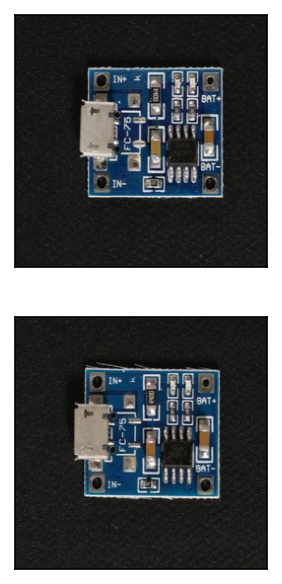

In [8]:
# Génération de masques
masks = generate_masks(data[:2].shape, k=16, n=3)
# Application des masques sur les images
data_masked = apply_masks(data[:2], masks)

display(data[:2], is_mask=False)

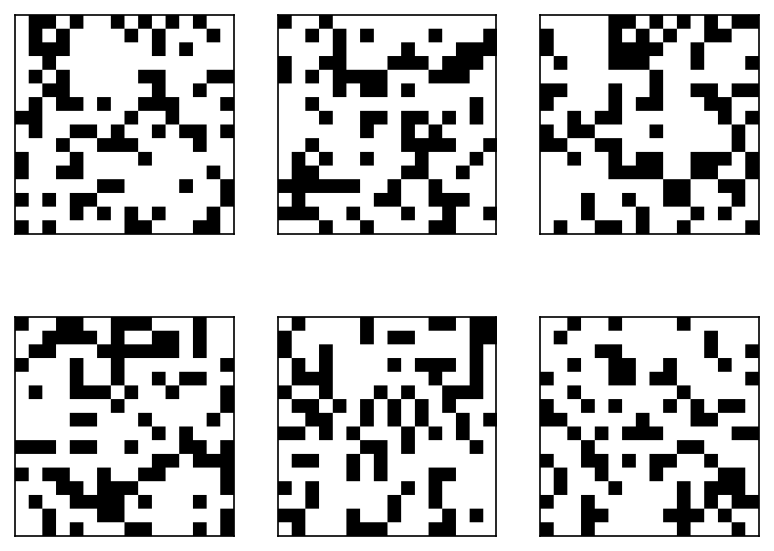

In [9]:
display(masks)

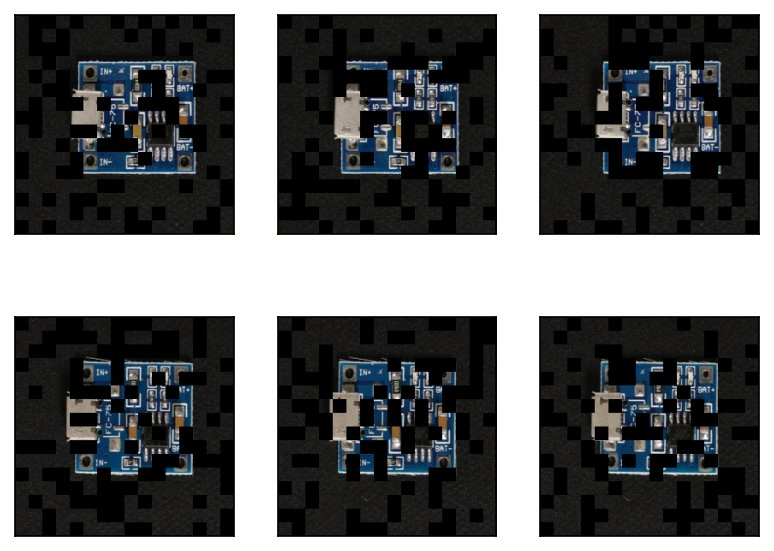

In [10]:
display(data_masked)

Les masques sont exclusifs, c'est-à-dire qu'ils ne recouvrent jamais une même partie de l'image. L'objectif du modèle sera de compléter les parties manquantes des données masquées puis de les réassembler.

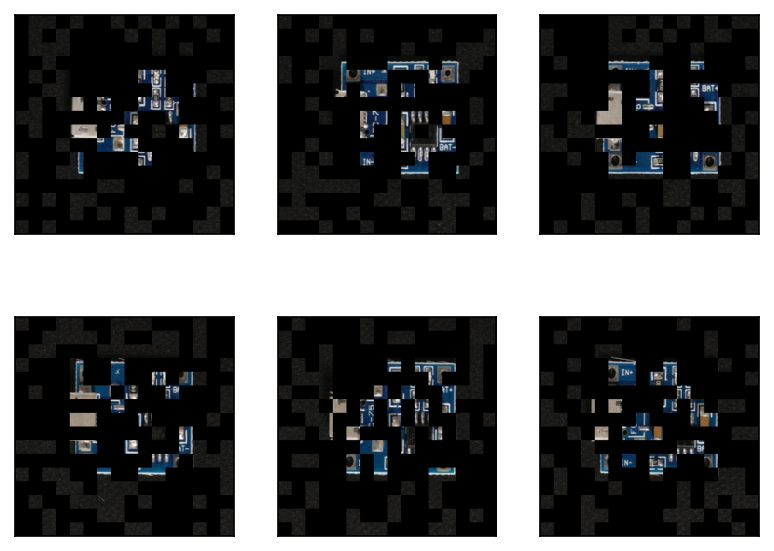

In [11]:
inverse_masked = apply_masks(data[:2], 1 - masks)
display(inverse_masked)

## Fonction de coût


La fonction de coût pour la méthode est calculée à partir de la *Gradient magnitude similarity* et de la *Structural similarity index*.

### Gradient magnitude similarity (GMS)


La GMS repose sur le calcul d'un gradient $g(I)$ sur les images considérées :

$$g(I)=\sqrt{(I*h_x)^2+(I*h_y)^2}$$

avec $*$ l'opérateur de convolution, $I$ l'image et le couple $h_x$ et $h_y$ les filtres de Prewitt sur les dimensions $x$ et $y$ correspondant en général à :

$h_x=\begin{bmatrix} 
-1 & 0 & +1 \\
-1 & 0 & +1 \\
-1 & 0 & +1 
\end{bmatrix}$ et $h_y=\begin{bmatrix} 
-1 & -1 & -1 \\
0 & 0 & 0 \\
+1 & +1 & +1
\end{bmatrix}$

$g(I)$ est donc la norme du gradient de l'image : la norme euclidienne du vecteur formé par ses dérivées horizontale ($I*h_x$) et verticale ($I*h_y$).


In [12]:
# Vectorized
def prewitt_filter(img: tf.Tensor, c=1e-9) -> tf.Tensor:
  # Define kernel for x differences
  if len(img.shape) < 4:
    im = tf.reshape(img, (1,) + img.shape)
  else:
    im = img
  kx = tf.broadcast_to(
    tf.constant(
      [[-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0], [-1.0, 0.0, 1.0]], shape=(3, 3, 1, 1)
    ),
    (3, 3, 3, 1),
  )
  # Define kernel for y differences
  ky = tf.broadcast_to(
    tf.constant(
      [[-1.0, -1.0, -1.0], [0.0, 0.0, 0.0], [1.0, 1.0, 1.0]], shape=(3, 3, 1, 1)
    ),
    (3, 3, 3, 1),
  )
  # Perform x convolution
  img_prewittx = (
    tf.nn.depthwise_conv2d(im, kx, strides=[1, 1, 1, 1], padding="SAME") / 3
  )
  # Perform y convolution
  img_prewitty = (
    tf.nn.depthwise_conv2d(im, ky, strides=[1, 1, 1, 1], padding="SAME") / 3
  )

  gmm = tf.math.sqrt(img_prewittx * img_prewittx + img_prewitty * img_prewitty + c)

  if len(img.shape) < 4:
    gmm = tf.reshape(gmm, img.shape)
  return gmm

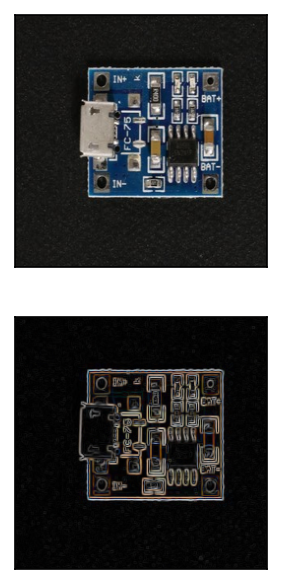

In [13]:
filtered_im = prewitt_filter(data[0])
display(tf.stack([data[0], filtered_im]), is_mask=False)

En utilisant $g(I)$, nous allons calculer la métrique de similarité GMS définie entre deux images $I$ et $I_r$ respectivement l'image originale et l'image reconstruite par l'auto-encodeur :

$GMS(I,I_r)= \frac{2g(I)g(I_r)+c}{g(I)^2+g(I_r)^2+c}$

avec $c$ une constante permettant la stabilité numérique.

In [14]:
# Vectorized.
def GMS(I: tf.Tensor, Ir: tf.Tensor, c=1e-9) -> tf.Tensor:
  gI = prewitt_filter(I)
  gIr = prewitt_filter(Ir)
  gms = (2 * gI * gIr + c) / (tf.math.square(gI) + tf.math.square(gIr) + c)
  return gms


# Tenseur de 1 si identique
print(tf.math.reduce_mean(GMS(data[:2], data[:2]), axis=(-1, -2, -3)))
# Tenseur différent de 1 si différent
print(tf.math.reduce_mean(GMS(data[:2], data[2:4]), axis=(-1, -2, -3)))

tf.Tensor([1. 1.], shape=(2,), dtype=float32)
tf.Tensor([0.7078323 0.7256751], shape=(2,), dtype=float32)


### Fonction de coût $L_G$
La GMS donne une valeur par pixel (et par canal) : la fonction de coût $L_G$ est la moyenne de son complément à 1 sur toute l'image :

$$L_G(I,I_r)=\frac{1}{HW}\sum_{i=1}^H\sum_{j=1}^W \left(1 - GMS(I,I_r)_{i,j}\right)$$

avec $H$ et $W$ la hauteur et la largeur de l'image (le code fait aussi la moyenne sur les canaux). Elle vaut 0 pour deux images identiques.

In [15]:
# Vectorized. Take one image per argument
def L_G(I: tf.Tensor, Ir: tf.Tensor) -> tf.Tensor:
  if len(I.shape) < 4:
    return tf.math.reduce_mean(1 - GMS(I, Ir))
  return tf.math.reduce_mean(1 - GMS(I, Ir), axis=(-1, -2, -3))


# Vaut zero en cas d'identité
print(L_G(data[:2], data[:2]))
# Non nul en cas de différence
# mais <dim*dim2
print(L_G(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.2921677 0.274325 ], shape=(2,), dtype=float32)


Plutôt que d'utiliser GMS, nous allons utiliser sa version multi-échelle $MSGMS(I,I_r)$, c'est-à-dire réduire volontairement plusieurs fois la taille des images à comparer et appliquer GMS à chaque fois. Les résultats sont ensuite moyennés. Cela va notamment permettre de "*lisser*" les résultats.

Dans le papier original MSGMS est calculé avec un average pooling de (2), jusqu'au huitième de la dimension initiale.

$$ MSGMS(I,I_r) = \frac{1}{|S|}\sum_{s\in S} GMS(I_s,I_{r,s})$$

avec $S$ l'ensemble des formats des images réduites, $I_s$ et $I_{r,s}$ les images $I$ et $I_r$ redimensionnées au format $s$

In [16]:
# Vectorized.
def MSGMS(I: tf.Tensor, Ir: tf.Tensor, is_loss=True) -> tf.Tensor:
  total_loss = GMS(I, Ir)

  for _ in range(3):
    I = tf.nn.avg_pool2d(I, 2, strides=2, padding="VALID")
    Ir = tf.nn.avg_pool2d(Ir, 2, strides=2, padding="VALID")
    total_loss += tf.image.resize(GMS(I, Ir), total_loss.shape[1:-1])

  total_loss = total_loss / 4
  if is_loss:
    return 1 - tf.reduce_mean(total_loss, axis=(-1, -2, -3))
  return total_loss


# Version vectorisée
print(MSGMS(data[:2], data[:2]))
print(MSGMS(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.25405914 0.21811575], shape=(2,), dtype=float32)


### Indice de similarité structurel (SSIM)
L'indice SSIM est une mesure de similarité dédiée aux images, définie par [Wang et al.](https://www.cns.nyu.edu/pub/eero/wang03-reprint.pdf).

Il prend en compte 3 critères différents pour établir la similarité :
 * la luminance
 * le contraste 
 * la structure générale

La méthode est déjà implémentée dans TensorFlow : [**tf.image.ssim**](https://www.tensorflow.org/api_docs/python/tf/image/ssim). Nous utilisons la SSIM simple : sa version multi-échelle (`tf.image.ssim_multiscale`) donne des gradients `NaN` dès qu'un de ses scores intermédiaires est négatif, ce qui arrive avec les reconstructions d'un réseau qui débute son apprentissage. La SSIM donne un score par image, 1 pour deux images identiques : comme pour la GMS, la fonction de coût $L_S$ est son complément à 1 :

$$L_S(I,I_r)=1 - \text{SSIM}(I,I_r)$$

In [17]:
# Vectorized.
def L_S(I: tf.Tensor, Ir: tf.Tensor, max_val=1.0) -> tf.Tensor:
  # Max val is the maximum difference between values allowed
  matrix_ssim = tf.image.ssim(I, Ir, max_val)
  return 1 - matrix_ssim


# Vaut zero en cas d'identité
print(L_S(data[:2], data[:2]))
# Non nul en cas de différence
print(L_S(data[:2], data[2:4]))

tf.Tensor([0. 0.], shape=(2,), dtype=float32)
tf.Tensor([0.55061066 0.5501993 ], shape=(2,), dtype=float32)


### Fonction de coût finale
La fonction de coût $L$ que nous utiliserons est la somme pondérée des fonctions de coût $L_G$ et $L_S$, plus l'erreur de reconstruction :

$$L=\lambda_G L_G + \lambda_S L_S + L_2$$

avec $\lambda_G,\lambda_S$ les pondérations des fonctions de coût respectives $L_G, L_S$, et $L_2$ l'erreur quadratique moyenne de reconstruction, pixel par pixel, entre l'image et sa reconstruction. Dans le code, $L_G$ est calculée sur la version multi-échelle (MSGMS), et la perte est sommée sur les images du batch.

In [18]:
def loss_vad(
  y: tf.Tensor, y_hat: tf.Tensor, lambda_G: float = 1, lambda_S: float = 1
) -> tf.Tensor:
  return tf.reduce_sum(
    lambda_G * MSGMS(y, y_hat)
    + lambda_S * L_S(y, y_hat)
    + tf.math.reduce_mean((y - y_hat) ** 2, axis=(-1, -2, -3))
  )


# Vaut zero en cas d'identité
print(loss_vad(data[:2], data[:2]))
# Non nul en cas de différence
print(loss_vad(data[:2], data[2:4]))

tf.Tensor(0.0, shape=(), dtype=float32)
tf.Tensor(1.6214013, shape=(), dtype=float32)


## Création du modèle
Le modèle RIAD applique donc la technique de masquage pour retrouver les anomalies pouvant être présentes dans une image.

Pendant l'entraînement, on applique l'algorithme suivant :
 * Choix aléatoire d'une taille de bloc $k$ pour les masques, parmi 2, 4, 8 et 16 pixels (les quatre tailles que la carte d'erreur `map_error` combine ensuite)
 * Génération aléatoire et application des masques sur les images
 * Pour chaque image masquée, l'auto-encodeur tente de reproduire l'image initiale.
 * Les parties masquées générées par l'auto-encodeur sont réassemblées pour former une seule image qui est ensuite comparée à l'image d'origine

Cet algorithme ne tient pas dans un `fit` ordinaire, qui applique le modèle une fois et compare sa sortie à une cible : la classe `RIAD` redéfinit donc l'étape d'entraînement, `train_step` (guide Keras [*Customizing what happens in `fit()`*](https://keras.io/guides/custom_train_step_in_tensorflow/)).
 * La perte est calculée dans `train_step` : `compile` ne reçoit que l'optimiseur.
 * Des `keras.metrics.Mean` moyennent les pertes sur l'epoch : ce sont ces moyennes que `fit` affiche et que suivent `EarlyStopping` et `ModelCheckpoint`, et non la valeur du dernier batch.
 * `fit` garde tout le reste : batches, epochs, callbacks.

In [19]:
class RIAD(keras.Model):
  def __init__(self, *args, **kwargs):
    super().__init__(*args, **kwargs)
    # Moyennes des pertes sur l'epoch, que fit affiche et que les callbacks suivent
    self.loss_tracker = keras.metrics.Mean(name="loss")
    self.loss_g_tracker = keras.metrics.Mean(name="loss_g")
    self.loss_s_tracker = keras.metrics.Mean(name="loss_s")
    self.l2_tracker = keras.metrics.Mean(name="l2")

  @property
  def metrics(self):
    # Keras remet à zéro les métriques de cette liste au début de chaque epoch
    return [
      self.loss_tracker,
      self.loss_g_tracker,
      self.loss_s_tracker,
      self.l2_tracker,
    ]

  def train_step(self, data):
    # fit(data) sans cible : data est le batch d'images lui-même
    x = data
    # Taille de bloc 2**k parmi 2, 4, 8 et 16, comme dans map_error
    k = tf.random.uniform((), minval=1, maxval=5, dtype=tf.int32)
    masks = generate_masks(x.shape, 2**k, 3)
    nb_masks = masks.shape[1]
    masked = apply_masks(x, masks)

    partial_xs = []
    with tf.GradientTape() as tape:
      for i in range(nb_masks):
        partial_xs.append(self(masked[:, i], training=True))  # Forward pass

      x_r = reconstruct_image(tf.stack(partial_xs, axis=1), masks)
      loss = loss_vad(x, x_r)

    # Calcul des gradients et mise à jour des poids
    gradients = tape.gradient(loss, self.trainable_variables)
    self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))

    # Mise à jour des moyennes, et leurs valeurs courantes pour l'affichage
    self.loss_tracker.update_state(loss)
    self.loss_g_tracker.update_state(MSGMS(x, x_r))
    self.loss_s_tracker.update_state(L_S(x, x_r))
    self.l2_tracker.update_state(tf.reduce_mean((x - x_r) ** 2))
    return {m.name: m.result() for m in self.metrics}

  def map_error(self, data):
    """Carte d'anomalie de chaque image du batch, à partir du score MSGMS."""
    mask_sizes = (2, 4, 8, 16)
    Ga = tf.zeros(data.shape)
    avg_filter = tf.ones((21, 21, 3, 1)) / (21 * 21 * 3)
    for k in mask_sizes:
      masks = generate_masks(data.shape, k, 3)
      nb_masks = masks.shape[1]
      masked = apply_masks(data, masks)

      partial_xs = []
      for i in range(nb_masks):
        partial_xs.append(self(masked[:, i], training=False))  # Forward pass

      x_r = reconstruct_image(tf.stack(partial_xs, axis=1), masks)
      Ga += 1 - MSGMS(data, x_r, False)
    Ga = Ga / len(mask_sizes)
    Ga = tf.nn.conv2d(Ga, avg_filter, strides=[1, 1, 1, 1], padding="SAME")
    return Ga

### Réseau U-Net

In [20]:
def downsample(inputs):
  return layers.MaxPooling2D(pool_size=(2, 2))(inputs)


def upsample(inputs):
  return layers.UpSampling2D(size=(2, 2))(inputs)


def semiblock(inputs, feature_maps):
  conv = layers.Conv2D(feature_maps, 3, activation="relu", padding="same")(inputs)
  batch_norm = layers.BatchNormalization()(conv)
  relu = layers.ReLU()(batch_norm)
  return layers.Dropout(0.1)(relu)


def block(inputs, feature_maps):
  return semiblock(semiblock(inputs, feature_maps), feature_maps)


def concat(*tensors):
  return layers.Concatenate()(list(tensors))


def unet(pretrained_weights=None, input_size=(256, 256, 3), starting_depth=64, steps=5):
  inputs = keras.Input(shape=input_size)
  encodings = []
  depths = [min(512, starting_depth * 2**i) for i in range(steps)]
  for depth in depths:
    encodings.append(block(downsample(encodings[-1]) if encodings else inputs, depth))
  x = encodings[-1]
  for depth, encoding in zip(depths[-2::-1], encodings[-2::-1]):
    x = block(concat(encoding, upsample(x)), depth)
  outputs = layers.Conv2D(
    3, 1, activation="sigmoid", padding="same", kernel_initializer="he_normal"
  )(x)

  model = RIAD(inputs, outputs)
  if pretrained_weights:
    model.load_weights(pretrained_weights)
  return model


# Construction du modèle
model = unet()

## Apprentissage
__ATTENTION__ : L'apprentissage peut être très long. 

Vous pouvez descendre directement à la partie `Visualisation avec des modèles pré-entraînés` si vous souhaitez juste voir le résultat.

In [21]:
callbacks = [
  keras.callbacks.EarlyStopping(monitor="loss", patience=20, restore_best_weights=True),
  keras.callbacks.ModelCheckpoint(
    "best_model.weights.h5",
    monitor="loss",
    mode="min",
    save_best_only=True,
    save_weights_only=True,
  ),
]
# Pas de loss : train_step calcule la perte lui-même
# Sans XLA : son compilateur n'a pas le redimensionnement « area » des masques, sur GPU
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), jit_compile=False)
history = model.fit(data, batch_size=5, epochs=1000, callbacks=callbacks)

Epoch 1/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 53s 705ms/step - l2: 0.1154 - loss: 5.7082 - loss_g: 0.3010 - loss_s: 0.7252
Epoch 2/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 736ms/step - l2: 0.0911 - loss: 4.8910 - loss_g: 0.2513 - loss_s: 0.6358
Epoch 3/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 744ms/step - l2: 0.0772 - loss: 4.4495 - loss_g: 0.2286 - loss_s: 0.5842
Epoch 4/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 744ms/step - l2: 0.0616 - loss: 4.1872 - loss_g: 0.2166 - loss_s: 0.5593
Epoch 5/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 740ms/step - l2: 0.0440 - loss: 3.8664 - loss_g: 0.2050 - loss_s: 0.5243
Epoch 6/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 739ms/step - l2: 0.0164 - loss: 3.3155 - loss_g: 0.1921 - loss_s: 0.4545
Epoch 7/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 739ms/step - l2: 0.0074 - loss: 2.6870 - loss_g: 0.1714 - loss_s: 0.3586
Epoch 8/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 738ms/step - l2: 0.0067 - loss: 2.5171 - loss_g: 0.1655 - loss_s: 0.3313
Epoch 9/1000
50/50 ━━━━━━━━━━━━━━━━━━━━ 37s 738ms/step - l2: 0.0

## Évaluations
Regardons les résultats de notre apprentissage, d'abord sur quelques images, puis sur tout le jeu de test (AUROC).

In [22]:
def error_vis(im, pred, err_map, ground=None, name=None):
  fig, ax = plt.subplots(
    len(im), 3 if ground is None else 4, figsize=(9, 4 * len(im)), squeeze=False
  )
  for j, title in enumerate(
    ["Carte d'anomalie", "Reconstruction", "Image", "Vérité terrain"]
  ):
    if j < ax.shape[1]:
      ax[0, j].set_title(title)
  for i in range(len(im)):
    for axi in ax[i]:
      axi.set_xticklabels([])
      axi.set_yticklabels([])
    ax[i, 0].imshow(im[i])
    ax[i, 0].imshow(err_map[i][0, ..., 0], alpha=0.5, cmap="jet")

    ax[i, 1].imshow(pred[i])
    ax[i, 2].imshow(im[i])

    if ground is not None:
      ax[i, 3].imshow(im[i])
      ax[i, 3].imshow(ground[i], cmap="jet", alpha=0.3)
  fig.tight_layout()
  if name is not None:
    fig.savefig(f"{name}.png")
  else:
    plt.show()


def display_err(objet: str, max_object: int = 5, good_data=False):
  model = unet(f"RIAD_models/best_model_{objet}.weights.h5")
  _, defect_data, good, ground = load_all(objet)
  defect_data = defect_data[:max_object]
  ground = ground[:max_object]
  good = good[:max_object]
  errors = []
  if good_data:
    for d in tqdm(good):
      errors.append(model.map_error(d[tf.newaxis, :]))

    res = model.predict(good)
    error_vis(good, res, errors, name=objet)
  else:
    for d in tqdm(defect_data):
      errors.append(model.map_error(d[tf.newaxis, :]))

    res = model.predict(defect_data)
    error_vis(defect_data, res, errors, ground, name=objet)


def anomaly_maps(model, images, batch_size=10):
  """Cartes d'anomalie (hauteur, largeur) de toutes les images, par lots."""
  maps = [
    model.map_error(images[i : i + batch_size])
    for i in trange(0, len(images), batch_size)
  ]
  return tf.concat(maps, axis=0).numpy()[..., 0]


def auroc(model, defect_data, goods, ground):
  """AUROC par image et par pixel, sur les images avec et sans anomalie."""
  maps = np.concatenate([anomaly_maps(model, defect_data), anomaly_maps(model, goods)])
  # Vérité terrain : 1 pour une image (un pixel) avec anomalie, 0 sinon
  image_labels = np.r_[np.ones(len(defect_data)), np.zeros(len(goods))]
  pixel_labels = np.concatenate(
    [ground.numpy()[..., 0] > 0.5, np.zeros((len(goods), *RESHAPE_DIM), dtype=bool)]
  )
  # Score d'une image : le maximum de sa carte d'anomalie
  image_scores = maps.max(axis=(1, 2))
  print(f"AUROC par image : {roc_auc_score(image_labels, image_scores):.3f}")
  print(f"AUROC par pixel : {roc_auc_score(pixel_labels.ravel(), maps.ravel()):.3f}")

### Données avec anomalies

In [23]:
# Les 10 premières images seulement, pour une figure lisible
errors = []
for d in tqdm(defect_data[:10]):
  errors.append(model.map_error(d[tf.newaxis, :]))

res = model.predict(defect_data[:10])

  0%|          | 0/10 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


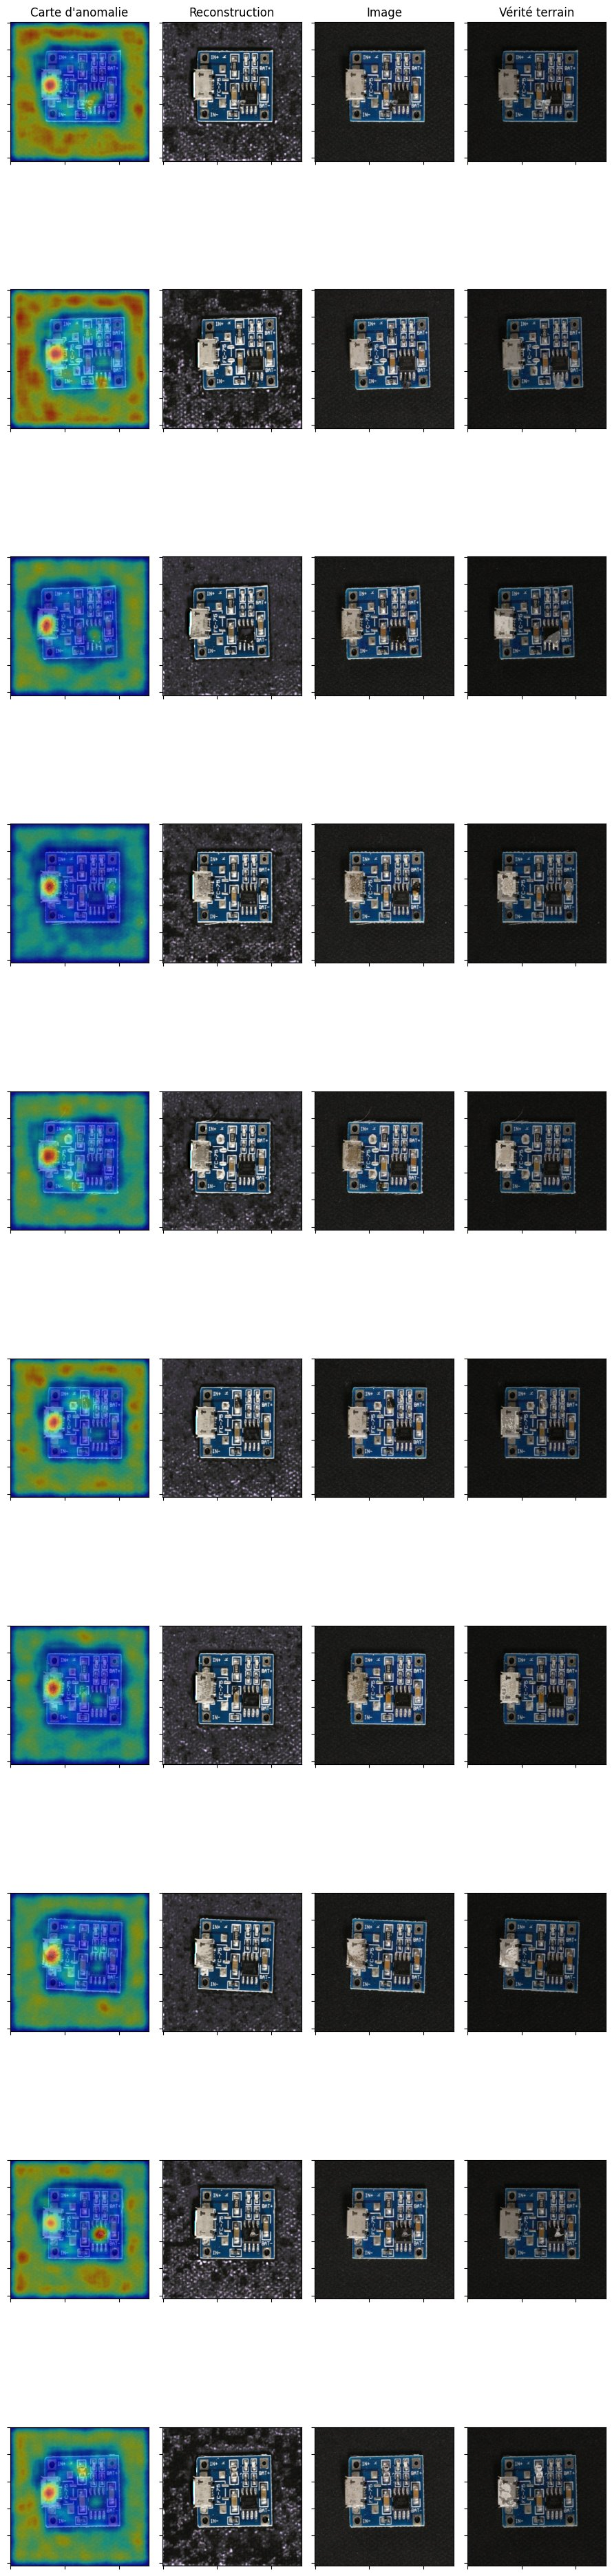

In [24]:
error_vis(defect_data[:10], res, errors, ground[:10])

### Données sans anomalies

In [25]:
err_goods = []
for d in tqdm(goods[:10]):
  err_goods.append(model.map_error(d[tf.newaxis, :]))

res_goods = model.predict(goods[:10])

  0%|          | 0/10 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step


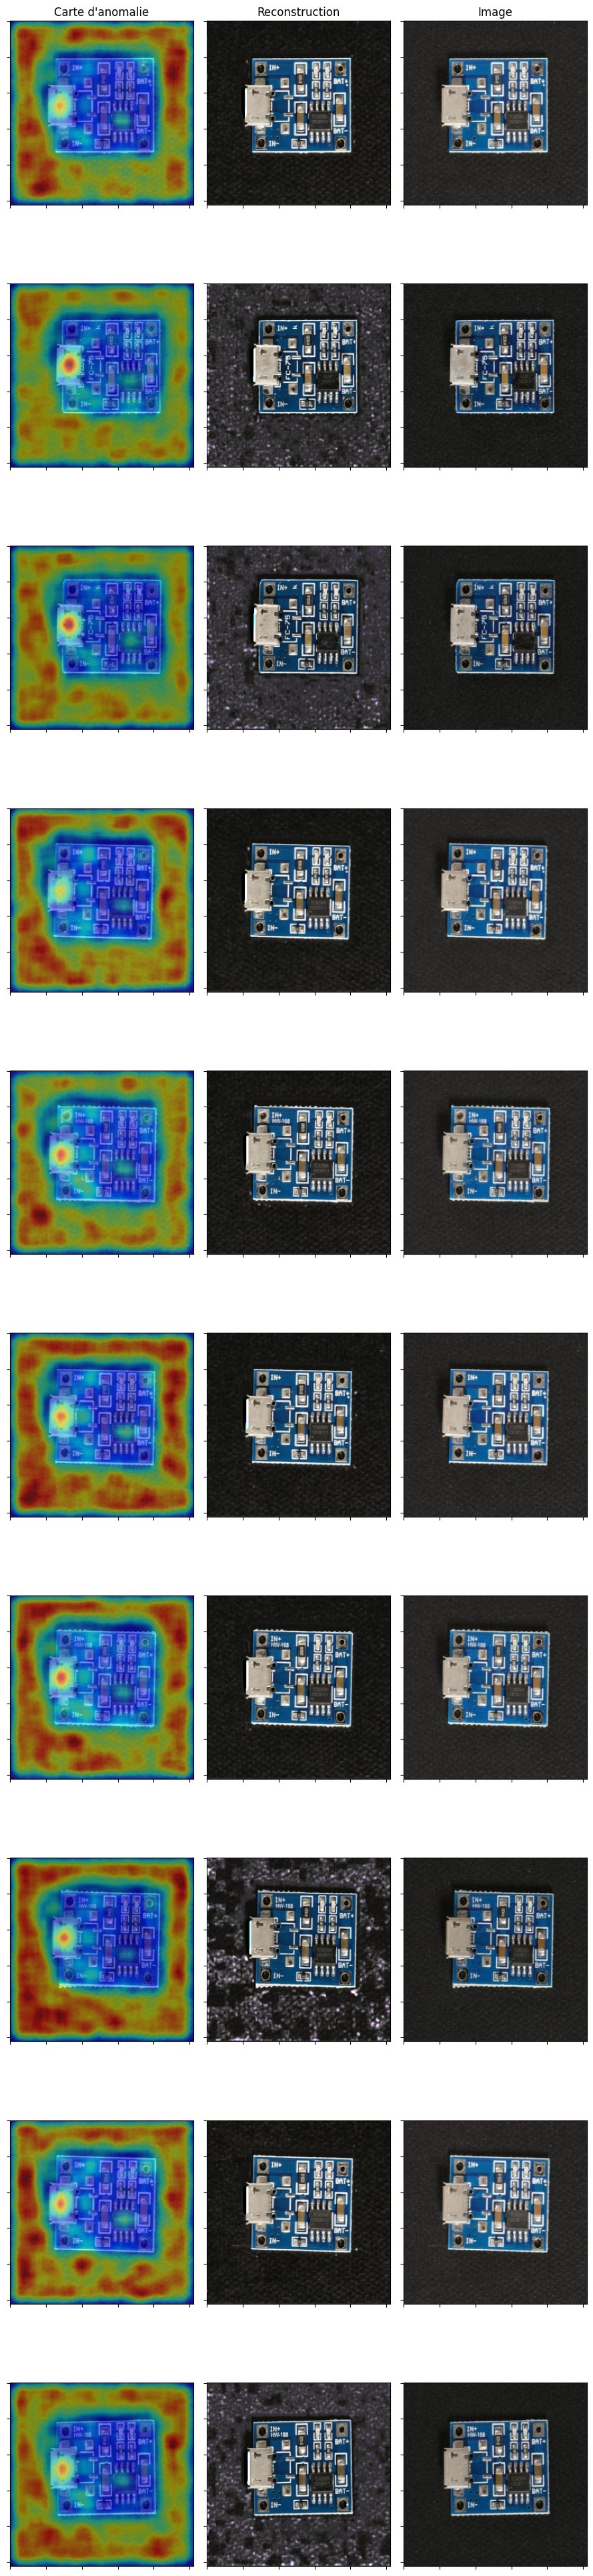

In [26]:
error_vis(goods[:10], res_goods, err_goods)

### Score sur tout le jeu de test
Les figures ne montrent que quelques images. Pour mesurer le détecteur sur tout le jeu de test, on calcule l'aire sous la courbe ROC (AUROC), la métrique des jeux de référence (MVTec AD, VisA) et de la bibliothèque anomalib :
 * **par image** : le score d'une image est le maximum de sa carte d'anomalie, et l'AUROC est la probabilité qu'une image avec anomalie ait un score plus élevé qu'une image normale (0,5 : hasard ; 1 : détecteur parfait) ;
 * **par pixel** : chaque pixel est classé selon sa valeur dans la carte d'anomalie, et comparé au masque de vérité terrain (les pixels des images normales sont tous normaux).

In [27]:
auroc(model, defect_data, goods, ground)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/11 [00:00<?, ?it/s]

AUROC par image : 0.848
AUROC par pixel : 0.693


## Visualisation avec des modèles pré-entraînés

### Données avec anomalies

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step


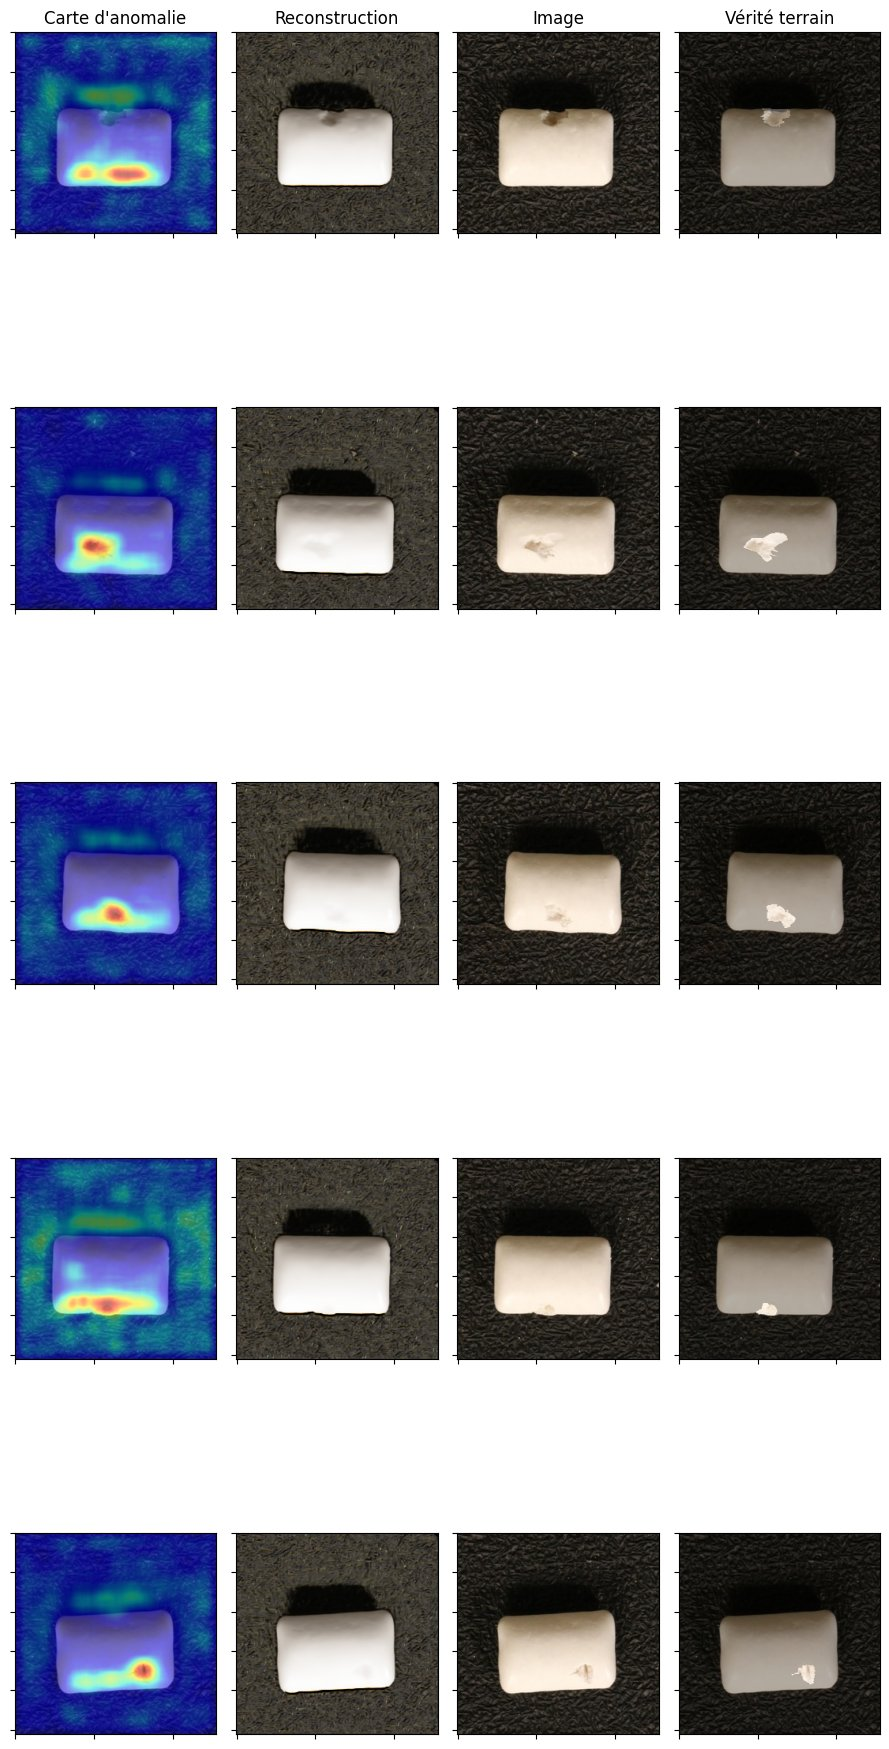

In [28]:
objet = "chewinggum"
display_err(objet)

### Données sans anomalie


  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


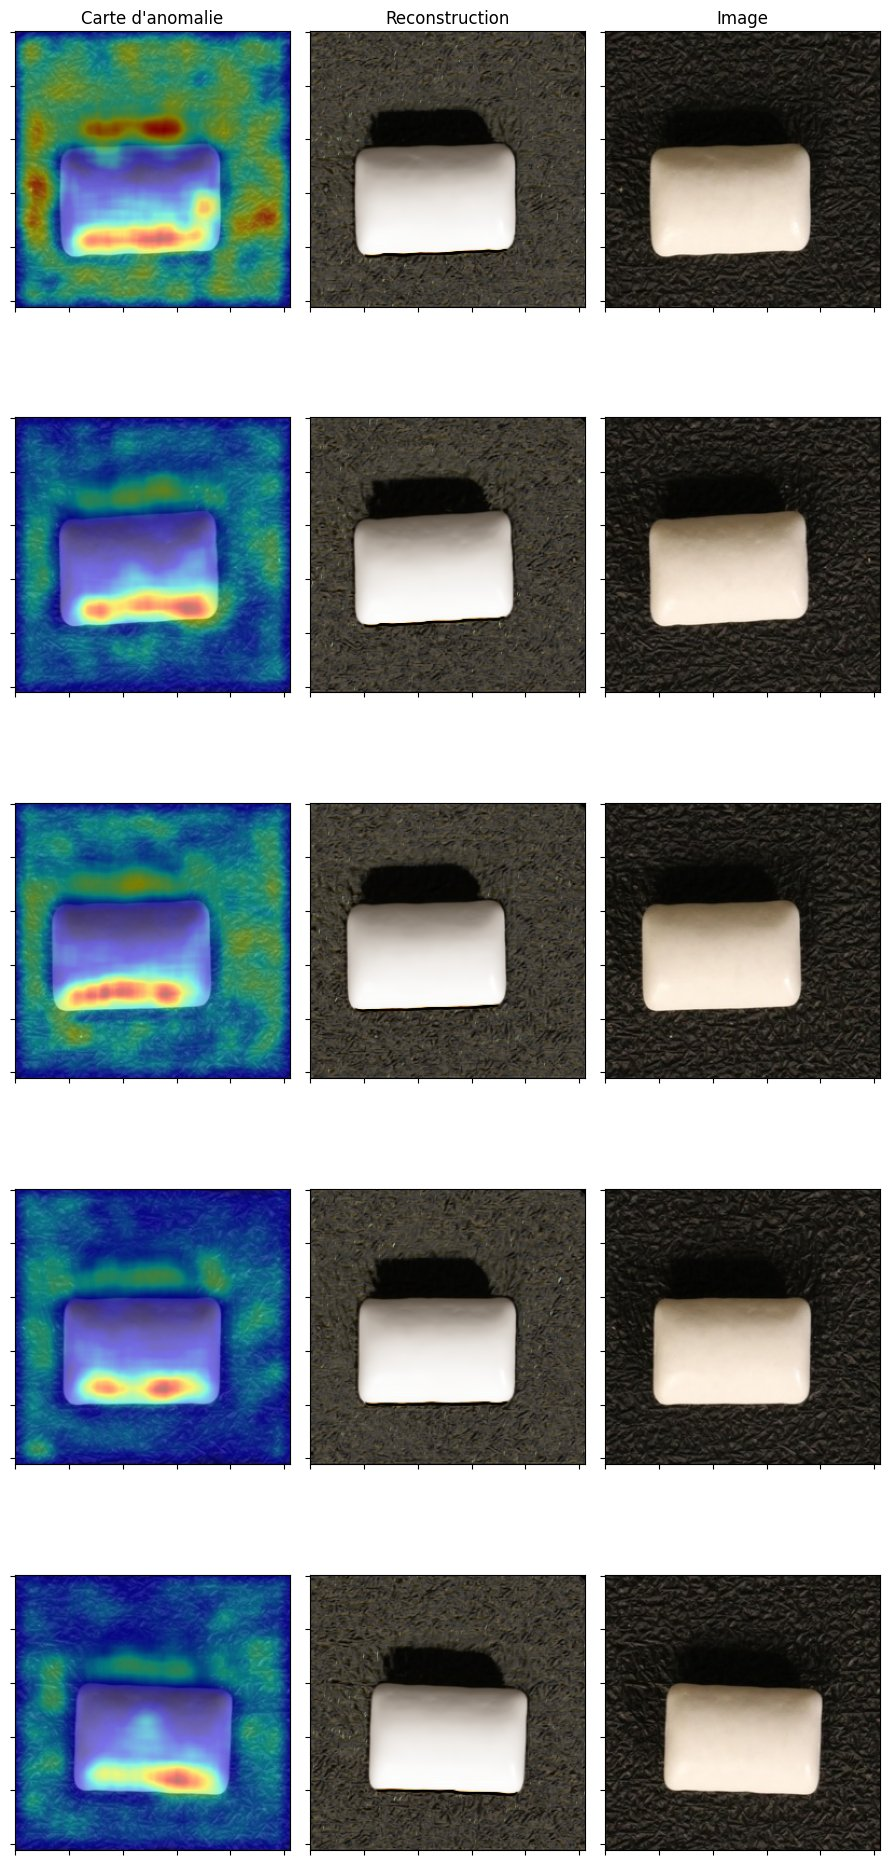

In [29]:
display_err(objet, good_data=True)

### Score du modèle pré-entraîné
Le même calcul d'AUROC, sur tout le jeu de test du chewing-gum.

In [30]:
_, defect_data_gum, goods_gum, ground_gum = load_all(objet)
auroc(
  unet(f"RIAD_models/best_model_{objet}.weights.h5"),
  defect_data_gum,
  goods_gum,
  ground_gum,
)

  0%|          | 0/250 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

AUROC par image : 0.736
AUROC par pixel : 0.858
